# Семинар по теме «Деревья классификации»

Во второй части семинара изучим деревья классификации и посмотрим, чем они отличаются от деревьев регрессии.

В случае дерева классификации целевая переменная категориальная (например, класс «съедобный» или «ядовитый» гриб), и дерево стремится разделить данные на подгруппы, максимально однородные по классам. Это отличается от дерева регрессии, где целевая переменная непрерывна и дерево стремится к однородности числового значения в узлах.

Из этого семинара ты узнаешь:
- как высчитывать критерии Джини и энтропии на практике;
- всегда ли полное неограниченное дерево приводит к переобучению (спойлер: не всегда);
- как написать свой класс деревьев и настроить его.

## Краткая теория

В дереве классификации есть две самые распространённые меры неопределённости: это критерий Джини и энтропия.

Критерий Джини задаётся как

$$H(R) = \sum_{k=1}^{K} \hat{p_k} (1 - \hat{p_k}).$$

Энтропия — это

$$H(R) = - \sum_{k=1}^{K} \hat{p_k} \log \hat{p_k}.$$

Посмотрим на бинарном примере, как работают эти две меры.

In [ ]:
def entropy(probs):
    """Вычисление энтропии по списку вероятностей классов."""
    ent = 0.0
    for p in probs:
        if p > 0:   # важно: 0 * log2(0) считаем как 0
            ent -= p * np.log2(p)
    return ent

def gini(probs):
    """Вычисление индекса Джини по списку вероятностей классов."""
    return 1 - sum(p**2 for p in probs)

###Задание 1 (0.5 балла)

<!--Используя реализованные выше функции entropy() и gini(), вычисли значения энтропии и индекса Джини для бинарного случая, когда вероятность попадания объекта в класс 0 (p₀) принимает значения от 0 до 1 с шагом 0.05 (соответственно вероятность класса 1 равна p₁ = 1 - p₀)-->

Реализуй такой кейс: вероятность попадания объекта в класс `0` ($p₀$) принимает значения от 0 до 1 с шагом `0.05`, а вероятность класса `1` равна $p₁ = 1 - p₀$. Вычисли значения энтропии и индекса Джини для бинарного случая. Используй для этого задания реализованные выше функции.

In [ ]:
import numpy as np

# Напиши код здесь
entropies = []
ginis = []
probabilities = np.arange(0, 1.01, 0.05)

for p in probabilities:
    entropies.append(entropy([p, 1-p]))
    ginis.append(gini([p, 1-p]))

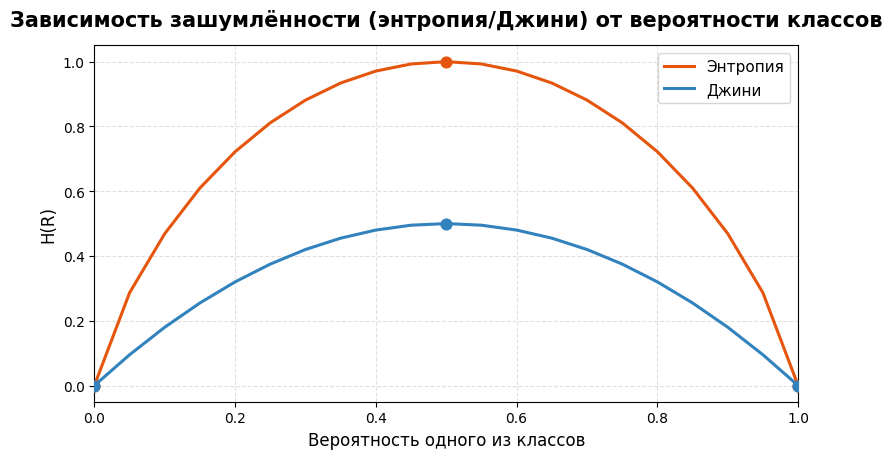

In [ ]:
import matplotlib.pyplot as plt

# Нарисуем график
plt.figure(figsize=(8, 4.7))
plt.plot(probabilities, entropies, label='Энтропия', color="#e6550d", linewidth=2.2)
plt.plot(probabilities, ginis, label='Джини', color="#3182bd", linewidth=2.2)

# Отметим максимум и минимум
plt.scatter([0, 1, 0.5], [entropies[0], entropies[-1], np.max(entropies)],
            color="#e6550d", s=60, zorder=5)
plt.scatter([0, 1, 0.5], [ginis[0], ginis[-1], np.max(ginis)],
            color="#3182bd", s=60, zorder=5)

plt.xlabel('Вероятность одного из классов', fontsize=12)
plt.ylabel('H(R)', fontsize=12)
plt.title('Зависимость зашумлённости (энтропия/Джини) от вероятности классов', fontsize=15, fontweight='bold', pad=14)
plt.legend(fontsize=11, frameon=True)
plt.grid(True, linestyle='--', alpha=0.38)
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Особой разницы между энтропией и Джини нет: они максимизируются при равных вероятностях двух классов и минимизируются, если одна из вероятностей ноль, а другая — единица.

## Данные

### EDA

In [ ]:
!pip install ucimlrepo --quiet

In [ ]:
# Импорт библиотек
from ucimlrepo import fetch_ucirepo
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

Сейчас мы поработаем с датасетом грибов (Mushroom Dataset), в котором 22 категориальных признака описывают гриб, а цель — определить, гриб съедобный или ядовитый. Все признаки категориальные, что даёт возможность разобраться, как дерево решений обрабатывает категориальные данные.

In [ ]:
mushroom = fetch_ucirepo(id=73)
X = mushroom.data.features     # Признаки
y = mushroom.data.targets   # Целевая переменная ('p' = poisonous, 'e' = edible)

print("Размерность X:", X.shape)
X.head()

Размерность X: (8124, 22)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


Обрати внимание, все признаки представлены буквами. Мы имеем дело с датасетом, в котором все признаки категориальные (а на предыдущем семинаре все признаки были численными).

Рассмотрим признаки датасета.

1. **Характеристики шляпки**

    1.1. `cap-shape` (форма шляпки: bell, conical, convex, flat, knobbed, sunken)  
    1.2. `cap-surface` (поверхность шляпки: fibrous, grooves, scaly, smooth)  
    1.3. `cap-color` (цвет шляпки: brown, buff, cinnamon, gray, green, pink, purple, red, white, yellow)  
    1.4. `bruises` (наличие синяков при надавливании: bruises, no)  
    1.5. `odor` (запах: almond, anise, creosote, fishy, foul, musty, none, pungent, spicy)  

2. **Признаки пластинок (gill)**

    2.1. `gill-attachment` (крепление пластинок к ножке: attached, descending, free, notched)  
    2.2. `gill-spacing` (расстояние между пластинками: close, crowded, distant)  
    2.3. `gill-size` (размер пластинок: broad, narrow)  
    2.4. `gill-color` (цвет пластинок: black, brown, buff, chocolate, gray, green, orange, pink, purple, red, white, yellow)  

3. **Признаки ножки (stalk)**

    3.1. `stalk-shape` (форма ножки: enlarging, tapering)  
    3.2. `stalk-root` (тип основания ножки: bulbous, club, cup, equal, rhizomorphs, rootless, missing)  
    3.3. `stalk-surface-above-ring` (поверхность ножки выше кольца: fibrous, scaly, silky, smooth)  
    3.4. `stalk-surface-below-ring` (поверхность ножки ниже кольца: fibrous, scaly, silky, smooth)  
    3.5. `stalk-color-above-ring` (цвет ножки выше кольца: brown, buff, cinnamon, gray, orange, pink, red, white, yellow)  
    3.6. `stalk-color-below-ring` (цвет ножки ниже кольца: brown, buff, cinnamon, gray, orange, pink, red, white, yellow)  

4. **Покрывала и кольца**

    4.1. `veil-type` (тип покрывала: partial)  
    4.2. `veil-color` (цвет покрывала: brown, orange, white, yellow)  
    4.3. `ring-number` (количество колец: none, one, two)  
    4.4. `ring-type` (тип кольца: cobwebby, evanescent, flaring, large, none, pendant, sheathing, zone)  

5. **Дополнительные признаки**

    5.1. `spore-print-color` (цвет спорового отпечатка: black, brown, buff, chocolate, green, orange, purple, white, yellow)  
    5.2. `population` (характер распространённости: abundant, clustered, numerous, scattered, several, solitary)  
    5.3. `habitat` (среда обитания: grasses, leaves, meadows, paths, urban, waste, woods)  


**Начнём с изучения целевой переменной.**

Целевая переменная $y$ — это метка класса: `'p'` (ядовитый) или `'e' `(съедобный). Посмотрим на распределение $y$.

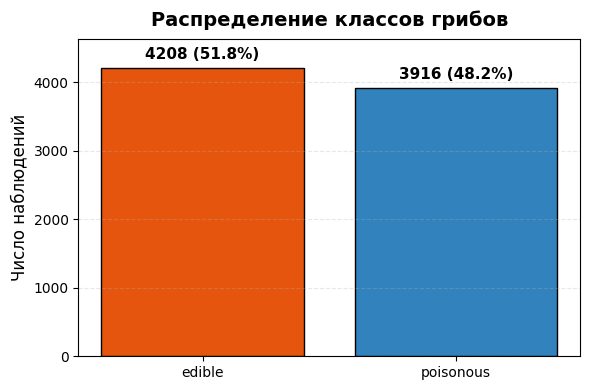

In [ ]:
# 1) Приведём y к одномерному вектору
y_flat = np.asarray(y).ravel()

# 2) Создадим Series и заменим метки
y_series = pd.Series(y_flat).replace({'p': 'poisonous', 'e': 'edible'})

# 3) Посчитаем количество и доли каждого класса
counts = y_series.value_counts()
percentages = (counts / len(y_series)) * 100

# 4) Построим barplot
plt.figure(figsize=(6, 4))

# Цвета для каждого столбца
colors = ['#e6550d', '#3182bd']
bars = plt.bar(counts.index, counts.values, color=colors, edgecolor='black')

plt.title("Распределение классов грибов", fontsize=14, fontweight='bold', pad=10)
plt.xlabel("")
plt.ylabel("Число наблюдений", fontsize=12)

# Добавим подписи над каждым столбцом
max_count = counts.max()
for bar in bars:
    height = bar.get_height()
    label = f"{int(height)} ({height / len(y_series) * 100:.1f}%)"
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + max_count * 0.02,  # чуть выше самого высокого столбца
        label,
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.ylim(0, max_count * 1.10)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Замечательная новость: наша целевая переменная распределена примерно равномерно (52 на 48). Это значит, что дополнительных манипуляций $y$ не требует.

Однако если бы мы наблюдали значительный дисбаланс (например, 70 на 30 или 80 на 20), нужно было бы балансировать классы (например, с помощью гиперпараметра `class_weight` в sklearn `DecisionTreeClassifier`). Это нужно было бы сделать потому, что дерево чувствительно к распределению классов, и при серьёзном дисбалансе может стать «ленивым», и почти всегда предсказывать наибольший класс (с точки зрения критерия Джини / энтропии это даёт вполне низкую ошибку).

In [ ]:
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   poisonous  8124 non-null   object
dtypes: object(1)
memory usage: 63.6+ KB


Еще одна замечательная новость: в целевой переменной нет пропусков.

Стоит помнить, что для `DecisionTreeClassifier` из `scikit-learn` не обязательно кодировать метки как 0/1.
Можно использовать любые строковые (или вообще любые хешируемые) значения. Поэтому мы оставим значения целевой переменной в виде строк и не будем их бинаризировать.

Перейдём теперь к анализу признаков.

Выше мы узнали, что все признаки являются категориальными. Проверим это.

In [ ]:
# Типы признаков
print("Типы признаков:")
print(X.dtypes.value_counts())

Типы признаков:
object    22
Name: count, dtype: int64


Также посмотрим на наличие пропусков в признаках.

In [ ]:
# Проверка пропусков
na_ratio = X.isnull().mean()
if na_ratio.sum() == 0:
    print("Пропусков в признаках нет.")
else:
    print("Признаки с пропусками:")
    print(na_ratio[na_ratio > 0].sort_values(ascending=False))

Признаки с пропусками:
stalk-root    0.305268
dtype: float64


In [ ]:
 # Все признаки категориальные, есть один признак с NaN
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   cap-shape                 8124 non-null   object
 1   cap-surface               8124 non-null   object
 2   cap-color                 8124 non-null   object
 3   bruises                   8124 non-null   object
 4   odor                      8124 non-null   object
 5   gill-attachment           8124 non-null   object
 6   gill-spacing              8124 non-null   object
 7   gill-size                 8124 non-null   object
 8   gill-color                8124 non-null   object
 9   stalk-shape               8124 non-null   object
 10  stalk-root                5644 non-null   object
 11  stalk-surface-above-ring  8124 non-null   object
 12  stalk-surface-below-ring  8124 non-null   object
 13  stalk-color-above-ring    8124 non-null   object
 14  stalk-color-below-ring  

Посмотрим теперь на распределение каждого из признаков.

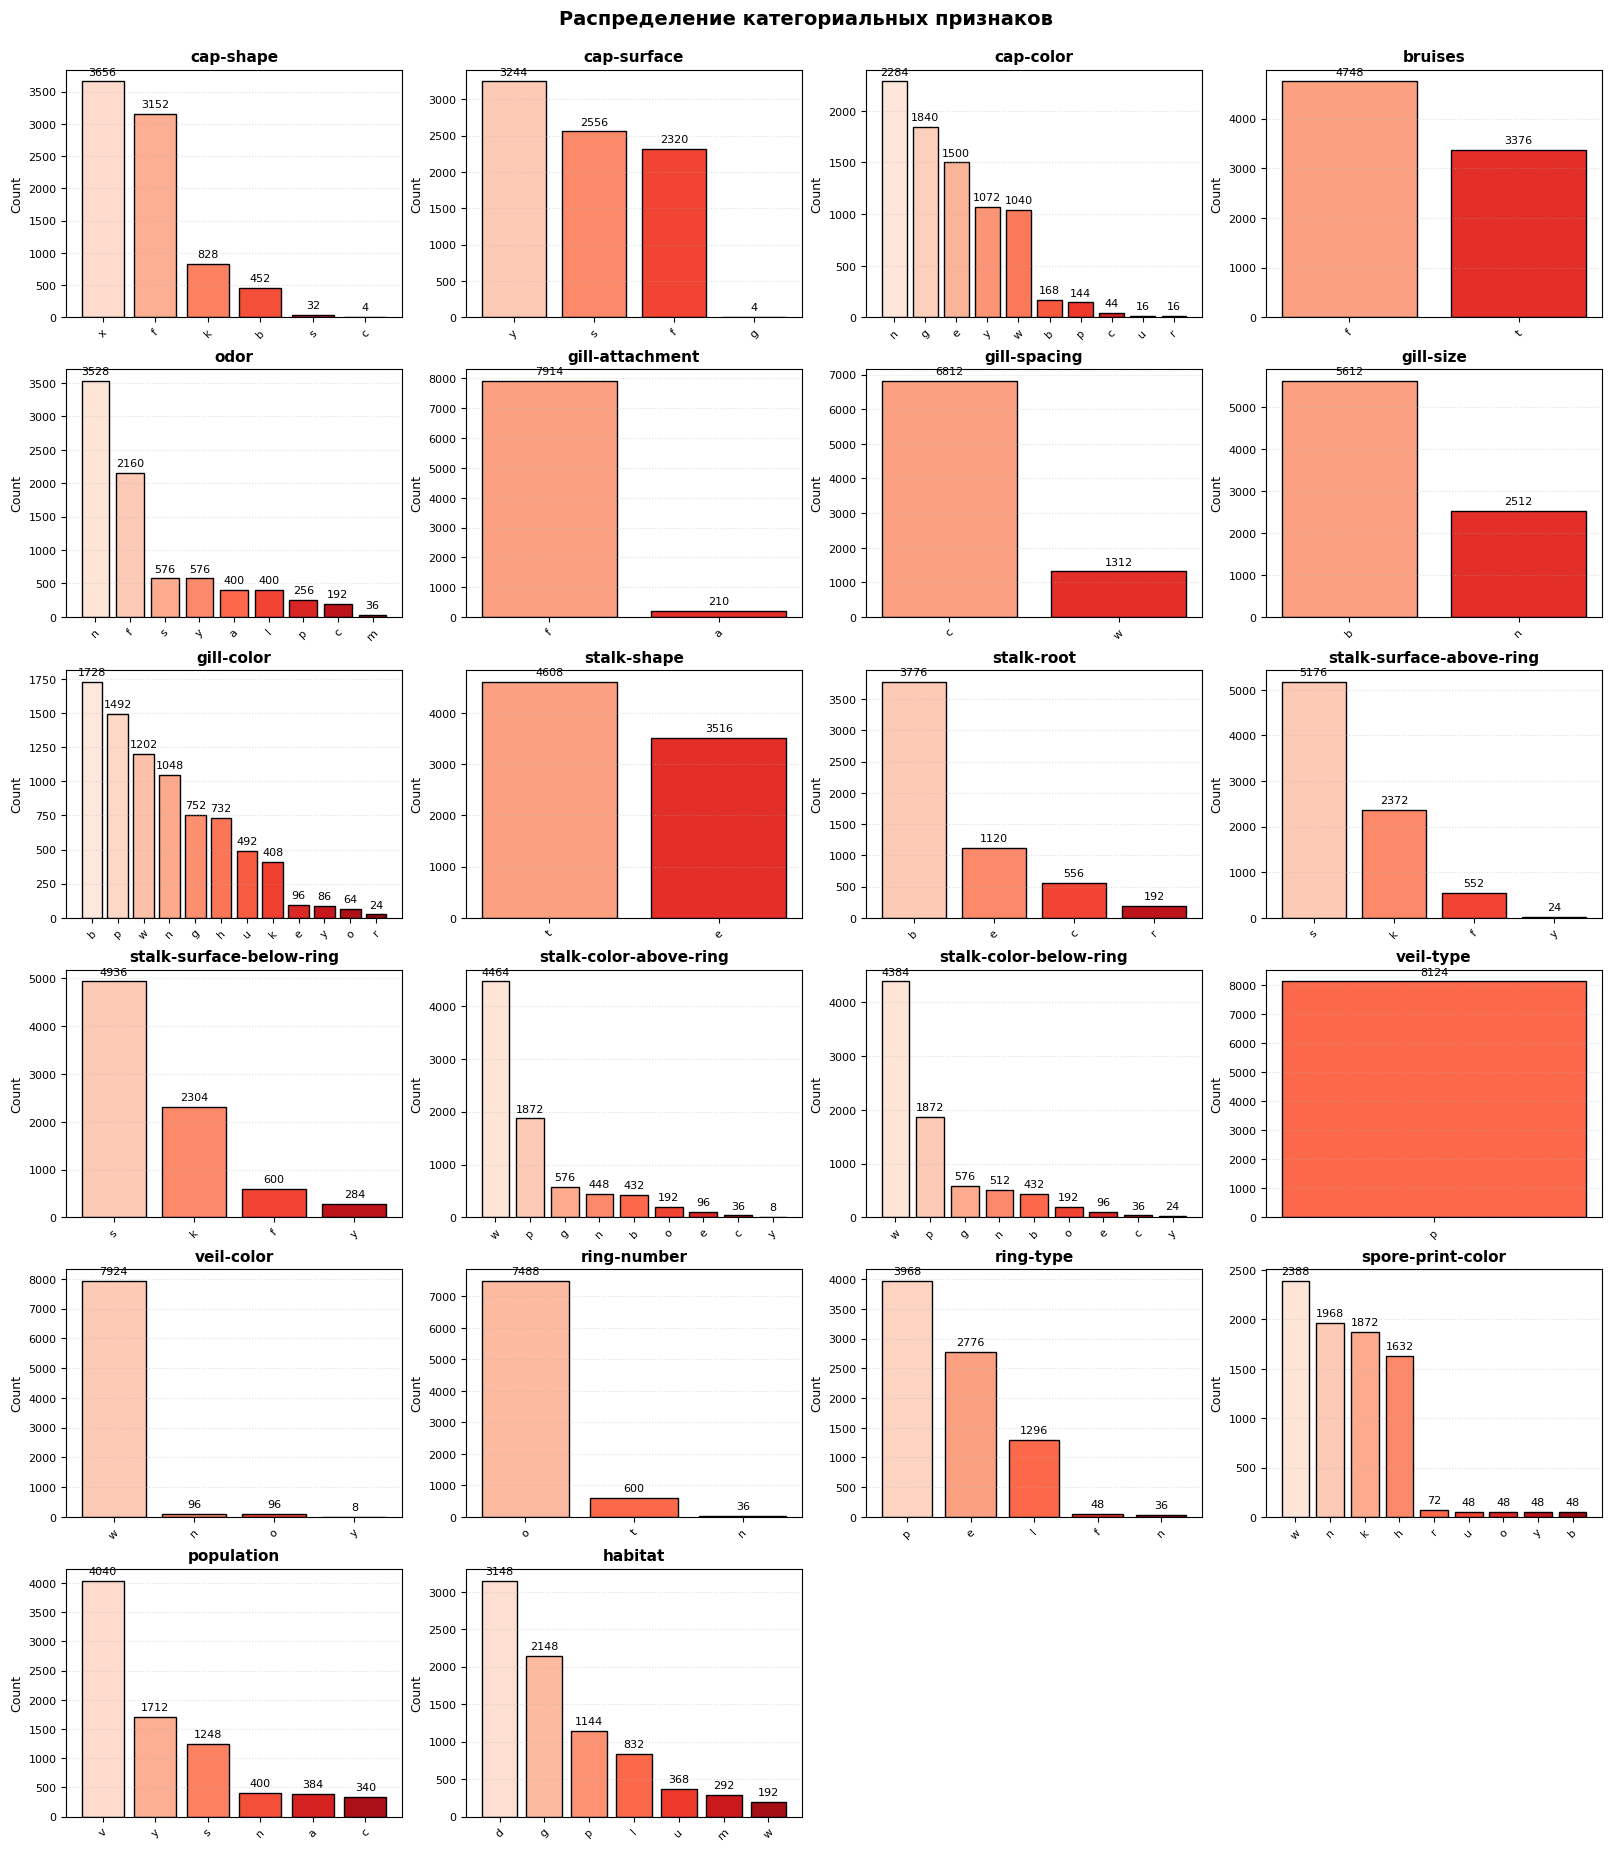

In [ ]:
cat_cols = X.columns.tolist()
n_features = len(cat_cols)

# Настроим сетку: 4 колонки, подсчитаем строки
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3), constrained_layout=True)
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    ax = axes[idx]
    counts = X[col].value_counts()
    categories = counts.index.tolist()
    values = counts.values

    # Построим bars
    bars = ax.bar(
        categories,
        values,
        color=sns.color_palette("Reds", len(categories)),
        edgecolor='black'
    )
    ax.set_title(f"{col}", fontsize=11, fontweight='bold')
    ax.set_xlabel("")
    ax.set_ylabel("Count", fontsize=9)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis="y", linestyle=":", alpha=0.4)

    # Добавим подписи над каждым баром
    max_val = values.max()
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + max_val * 0.02,
            f"{int(height)}",
            ha='center',
            va='bottom',
            fontsize=8
        )

# Делаем так, чтобы последние две диаграммы в последней строчке не нарисовались пустыми
for j in range(n_features, n_rows * n_cols):
    fig.delaxes(axes[j])

plt.suptitle("Распределение категориальных признаков", fontsize=14, fontweight='bold', y=1.02)
plt.show()

Здесь мы видим, что, например, признак `veil-type` принимает всего одно возможное значение. Таким образом, этот признак абсолютно бесполезен, и, удалив его, мы сделаем наши данные чище.

In [ ]:
X = X.drop('veil-type', axis=1)

In [ ]:
X.shape

(8124, 21)

В целом, больше ничего делать тут не нужно. Мы видим, что некоторые значения некоторых признаков встречаются достаточно редко, и, в теории, при обучении неограниченного дерева это может привести к переобучению на редких значениях. Тем не менее, в этом семинаре мы будем обучать дерево и сразу его «стричь», так что редкие значения не представляют для нас угрозы.

### Препроцессинг

Как и в семинаре с регрессией, проведём препроцессинг по результатам нашего разведывательного анализа данных.

In [ ]:
# В stalk-root есть NA, заменим их модой
root_mode = X["stalk-root"].mode(dropna=True)[0]

# Заполняем пропуски модой
X = X.fillna(root_mode)

Теперь подготовим данные для моделирования. Дерево решений в sklearn не умеет напрямую работать с категориальными признаками в виде строк. Необходимо превратить их в численные. Самый распространённый способ — one-hot encoding.

In [ ]:
X_encoded = pd.get_dummies(X, dtype=int)
X_encoded.head()

,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


In [ ]:
X_encoded.shape

(8124, 115)

Мы видим, что one-hot encoding привёл к увеличению количества признаков с 21 до 115. Стоит помнить, что этот dummy-метод по работе с категориальными признаками применим только в случае, когда количество возможных значений в каждом признаке невелико. В нашем случае это как раз так и есть.

Как и всегда, разделим выборку на обучающую и тестовую.

In [ ]:
# Разделим на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

## Обучение дерева классификации в sklearn

Обучение деревьев классификации через библиотеку sklearn происходит похожим
образом, что и в регрессии.

In [ ]:
'''
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion='gini', # критерий расщепления
                                                 # «gini»/«entropy»
     splitter='best',               # разбиение  «best»/«random»
     max_depth=None,                # допустимая глубина
     min_samples_split=2,           # минимальная выборка для разбиения
     min_samples_leaf=1,            # минимальная мощность листа
     min_weight_fraction_leaf=0.0,  # аналогично с весом
     max_features=None,             # #признаков для нахождения разбиения
     random_state=3,
     max_leaf_nodes=None,           # допустимое число листьев
     min_impurity_decrease=0.0,     # порог изменения «зашумлённости»
     class_weight=None,             # веса классов («balanced» или словарь)
     ccp_alpha=0.0)                 # для подрезки

model.fit(X, y)
''';

Теперь обучим дерево классификации на данных из датасета Mushrooms, используя критерии Джини и энтропии. После обучения сразу проверим качество полного и постриженного деревьев.

В прошлом семинаре по регрессиям мы разобрались, что полное дерево часто ведёт к переобучению. Давай посмотрим, всегда ли это так и может ли полное дерево стать оптимальным вариантом.

###Задание 2 (1 балл)

1. Построй полное дерево классификации (датасет Mushrooms), используя критерии Джини и энтропии.

2. По примеру метода post-pruning из семинара по деревьям регрессии добавь post-pruning «стрижку» деревьев через гиперпараметр $\alpha$. Оцени для каждого значения $\alpha$ качество модели только на тестовом датасете. Так как классы целевого признака у нас сбалансированы, в качестве метрики используй точность (`accuracy`), посчитай её с помощью метода `model.score`.

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html#sklearn.tree.DecisionTreeClassifier.score

<!--У тебя должны получиться списки test_gini, test_entropy из значений качеств для каждого значения альфа, отдельно для критериев Джини и энтропии.-->

В результате должны получиться списки `test_gini` и `test_entropy`.


In [ ]:
# Напиши код здесь

# Джини
# 1) Определяем все значения альфы, при которых дерево сокращается
base_tree_gini = DecisionTreeClassifier(criterion='gini', random_state=0)
base_tree_gini.fit(X_train, y_train)
path = base_tree_gini.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas_gini = path.ccp_alphas

# 2) Посмотрим на качество модели для каждого значения альфы
test_gini = []
for alpha in ccp_alphas_gini:
    model = DecisionTreeClassifier(criterion='gini', random_state=0, ccp_alpha=alpha)
    model.fit(X_train, y_train)
    test_gini.append(model.score(X_test, y_test))

# Энтропия
# 1) Определяем все значения альфы, при которых дерево сокращается
base_tree_entropy = DecisionTreeClassifier(criterion='entropy', random_state=0)
base_tree_entropy.fit(X_train, y_train)
path = base_tree_entropy.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas_entropy = path.ccp_alphas

# 2) Посмотрим на качество модели для каждого значения альфы
test_entropy = []
for alpha in ccp_alphas_entropy:
    model = DecisionTreeClassifier(criterion='entropy', random_state=0, ccp_alpha=alpha)
    model.fit(X_train, y_train)
    test_entropy.append(model.score(X_test, y_test))

Нарисуем, как тестовая точность зависит от ограничивающего гиперпараметра $\alpha$ в случаях Джини и энтропии.

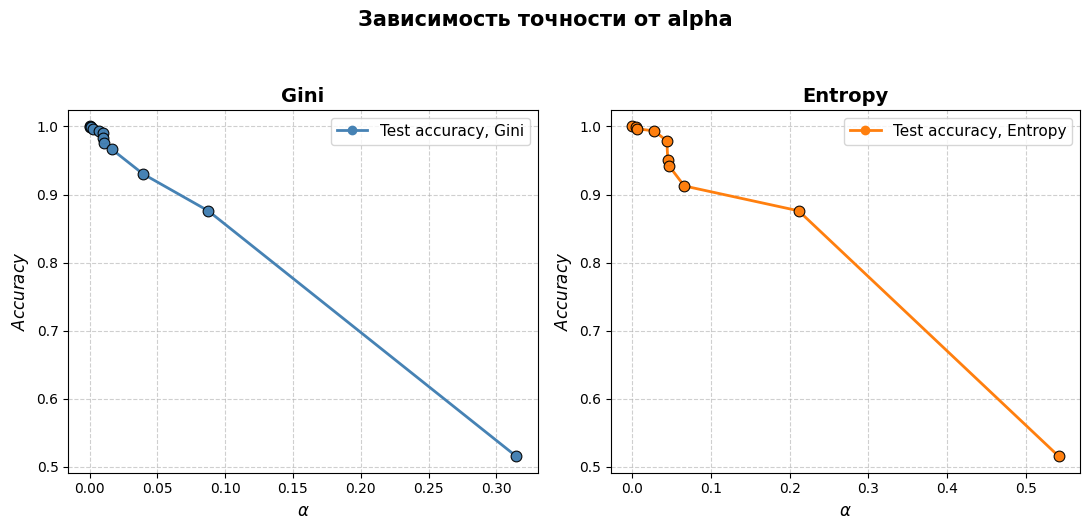

In [ ]:
plt.figure(figsize=(11, 5))
dot_kwargs = dict(s=60, zorder=5, edgecolor='black', linewidth=0.8, alpha=0.95)

# Gini
plt.subplot(1, 2, 1)
plt.plot(ccp_alphas_gini, test_gini, marker='o', color='#4682b4', label='Test accuracy, Gini', linewidth=2)
plt.scatter(ccp_alphas_gini, test_gini, color='#4682b4', **dot_kwargs)
plt.xlabel(r'$\alpha$', fontsize=12)
plt.ylabel(r'$Accuracy$', fontsize=12)
plt.title('Gini', fontsize=14, fontweight='bold')
plt.grid(True, ls='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()

# Entropy
plt.subplot(1, 2, 2)
plt.plot(ccp_alphas_entropy, test_entropy, marker='o', color='#ff7f0e', label='Test accuracy, Entropy', linewidth=2)
plt.scatter(ccp_alphas_entropy, test_entropy, color='#ff7f0e', **dot_kwargs)
plt.xlabel(r'$\alpha$', fontsize=12)
plt.ylabel(r'$Accuracy$', fontsize=12)
plt.title('Entropy', fontsize=14, fontweight='bold')
plt.grid(True, ls='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()

plt.suptitle("Зависимость точности от alpha", fontsize=15, fontweight='bold', y=1.05)
plt.subplots_adjust(top=0.85)
plt.show()

>Неограниченное и необрезанное дерево (для $\alpha$ = 0) даёт не просто лучшие, а идеальные предсказания на тестовых данных!

In [ ]:
# Обучим неограниченное дерево
base_tree_gini.fit(X_train, y_train)
base_tree_entropy.fit(X_train, y_train)

# Оценим качество на тестовой выборке
acc_gini = base_tree_gini.score(X_test, y_test)
acc_entropy = base_tree_entropy.score(X_test, y_test)
print(f"Точность на тесте (Джини): {acc_gini:.4f}")
print(f"Точность на тесте (Энтропия): {acc_entropy:.4f}")

Точность на тесте (Джини): 1.0000
Точность на тесте (Энтропия): 1.0000


In [ ]:
print('Глубина дерева(Джини):', base_tree_gini.get_depth())
print('Число листьев(Джини):', base_tree_gini.get_n_leaves())

print('Глубина дерева(Энтропия):', base_tree_entropy.get_depth())
print('Число листьев(Энтропия):', base_tree_entropy.get_n_leaves())

Глубина дерева(Джини): 7
Число листьев(Джини): 14
Глубина дерева(Энтропия): 5
Число листьев(Энтропия): 11


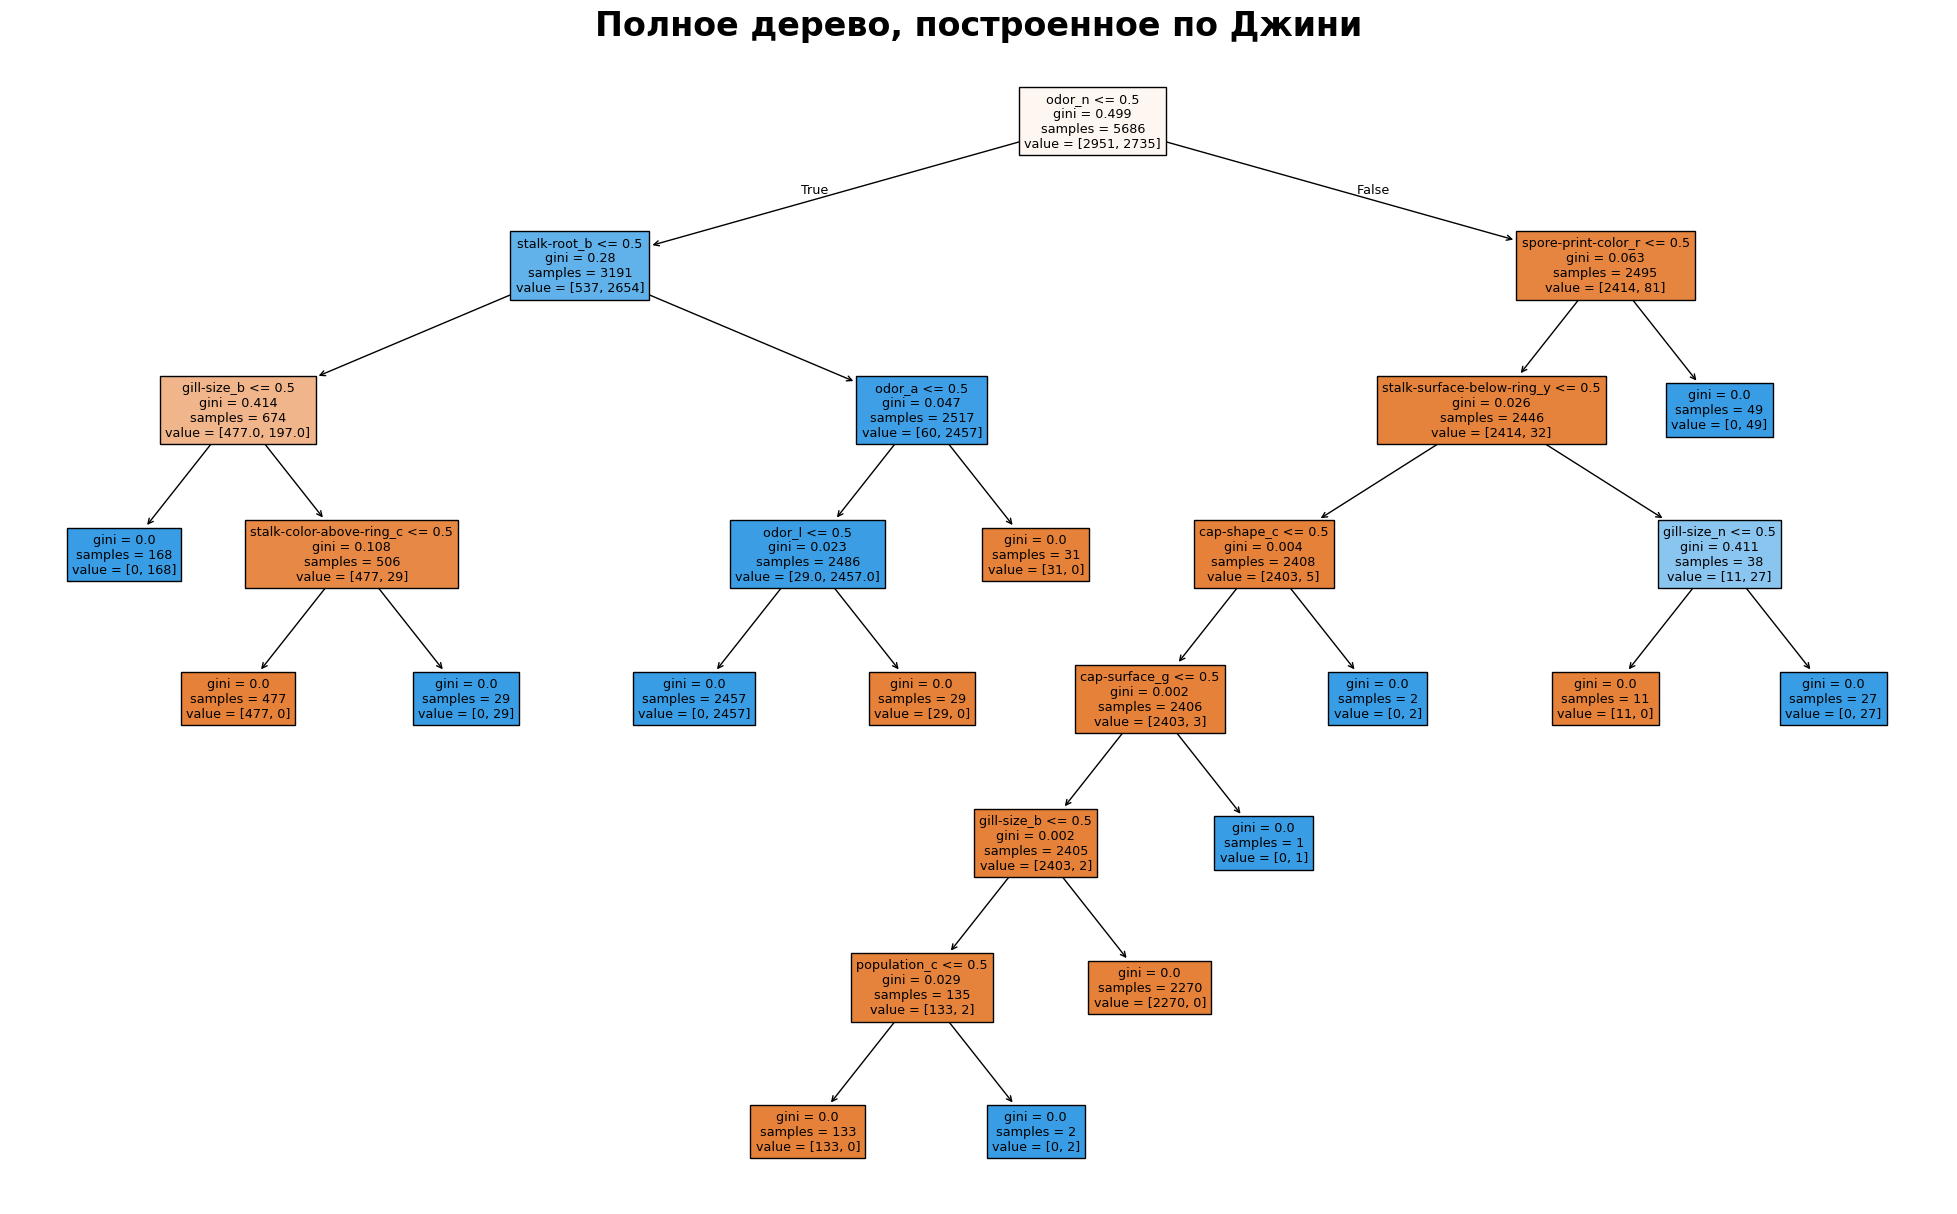

In [ ]:
plt.figure(figsize=(25,15))
tree.plot_tree(base_tree_gini, feature_names=X_encoded.columns, filled=True)#, max_depth=2)
plt.title("Полное дерево, построенное по Джини", fontsize=24, fontweight='bold', pad=10)
plt.show()

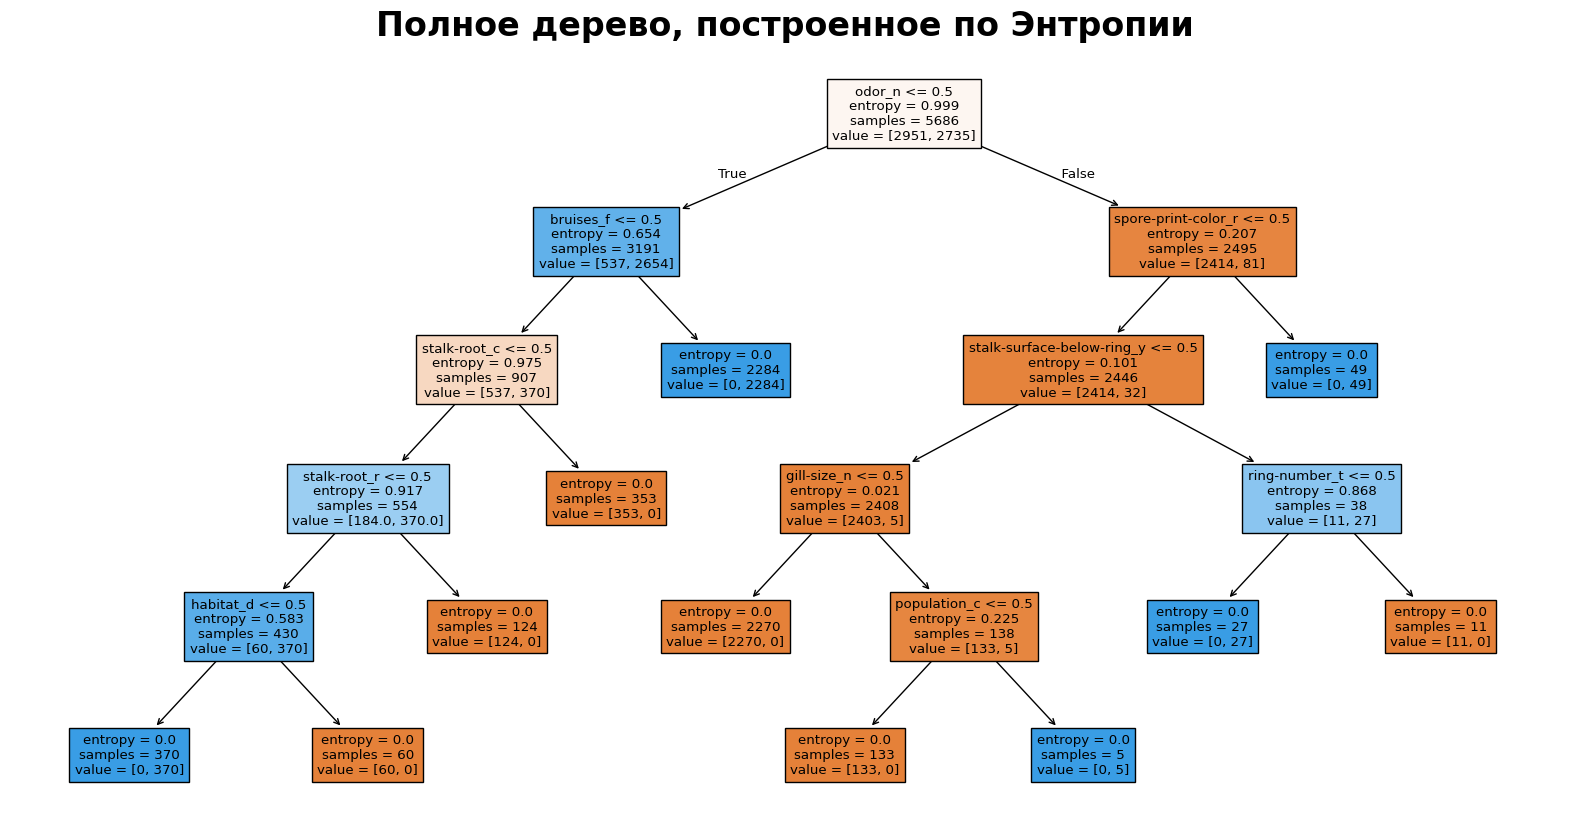

In [ ]:
plt.figure(figsize=(20,10))
tree.plot_tree(base_tree_entropy, feature_names=X_encoded.columns, filled=True)#, max_depth=2)
plt.title("Полное дерево, построенное по Энтропии", fontsize=24, fontweight='bold', pad=10)
plt.show()

У нас получился очень интересный результат: полное необрезанное дерево дало лучшие показатели качества на тестовых данных. И не просто лучшие: тестовая ошибка оказалась нулевой.

На самом деле дело не в деревьях, а в самих данных. Датасет Mushrooms практически идеально делится по нескольким категориальным признакам, главным образом по odor. На схеме видно, что разделение по odor происходит самым первым. Таким образом, этот датасет почти не имеет шума и противоречий: в нём нет примеров с одинаковыми признаками и разными метками. Поэтому любой алгоритм, который умеет отражать дискретные правила, всегда будет попадать в цель.

Но на практике это редкое явление. В большинстве случаев неограниченное дерево переобучается. Чтобы этого не было, надо вводить какие-то ограничения.

Интересно, что структура деревьев, сгенерированных по критериям Джини и энтропии, всё же отличается: деревья, построенные по разным критериям, часто будут отличаться в плане признаков и порогов, по которым происходят деления на каждом шаге. А в плане качества предсказаний разница на тестовых данных между энтропией и Джини незначительна.

<!-- Энтропия и Джини часто выдают примерно один и тот же перформанс на тестовых данных. -->






## Как написать свой класс деревьев

Пока мы пользовались готовыми реализациями из библиотеки sklearn: строили деревья решений, регулировали глубину, пробовали post-pruning и исследовали важность признаков. Всё работало «из коробки», но многие детали оставались скрыты, ведь sklearn — это чёрный ящик.

Сейчас ты начнёшь писать собственный мини-класс дерева классификации. Он нужен, чтобы:

* чётко понять, где и как считается прирост информации;
* увидеть, как рекурсивно растёт дерево и почему оно иногда «отказывается» делиться;
* получить базу для дальнейших действий: от кастомных критериев до экспериментов с визуализацией дерева.

Данные (`X_train`, `X_test`, `y_train`, `y_test`) уже готовы в памяти, поэтому сразу переходим к коду.

In [ ]:
!pip install ucimlrepo --quiet

In [ ]:
# Импорт библиотек
from ucimlrepo import fetch_ucirepo
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import seaborn as sns

Начнём со вспомогательного класса, добавим некоторые функции дерева и объединим всё в один класс деревьев классификации.

Вспомогательный класс `_Node` выделяется для того, чтобы у дерева решений было
единообразное представление каждой вершины.  Вместо того, чтобы хранить узлы как безымянные кортежи или словари и вспоминать, в каком индексе лежит порог, а в каком — метка, задаём объект с именованными полями.  Это резко повышает читаемость кода: в рекурсивных функциях появляется естественная запись `node.feat`, `node.left`, `node.is_leaf()` вместо цепочек индексов.

Один и тот же класс описывает как внутренние вершины, так и листья:

- если заполнены `feat`, `thr`, `left` и `right`, узел разделяющий;

- если заданы `proba` и `label`, а `feat` оставлен `None`, то это уже лист.

Такой подход избавляет от необходимости создавать два разных класса и писать двойную логику обхода.  Достаточно проверить одно условие — `node.is_leaf()` —, и код понимает, как действовать дальше.

In [ ]:
class _Node:
    """Вершина дерева (и внутренний узел, и лист)."""
    def __init__(self, feat=None, thr=None, left=None, right=None,
                 proba=None, label=None):
        self.feat = feat      # Индекс признака для сплита
        self.thr = thr        # Порог сплита
        self.left = left      # Левая ветка
        self.right = right    # Правая ветка
        self.proba = proba    # Вероятности классов (только в листе)
        self.label = label    # Метка класса (только в листе)

    def is_leaf(self):
        """Возвращает True, если вершина является листом."""
        return self.label is not None

In [ ]:
# Перед началом работы бинаризируем целевую переменную
# Также переведём значения игриков в формат array и будем работать с этим форматом

arr = np.asarray(y_train)
y_train = (arr == 'p').astype(int) if isinstance(arr[0][0], str) else arr.astype(int)

arr = np.asarray(y_test)
y_test  = (arr == 'p').astype(int) if isinstance(arr[0][0], str) else arr.astype(int)

###Задание 3 (0.5 балла)

Создадим лист дерева.

Когда подмножество объектов стало «достаточно однородным» или
достигнуты ограничения глубины/размера, прекращаем делить вершину и превращаем её в лист.  В листе нужно хранить:

*   `proba`  — распределение классов в этом подмножестве;
*   `label`  — индекс самого вероятного класса.

Ниже дана заготовка функции `_make_leaf`. На вход ты принимаешь массив вида array ([0, 1, 0, 0...]), состоящий из меток (0/1) каждого отдельного тренировочного наблюдения в какой-то вершине дерева. Мы хотим превратить эту вершину в лист. Твоя задача — вывести вероятности каждого класса и индекс самого вероятного класса в листе. Напомним, что вероятности каждого класса в листе считаются как доля наблюдений каждого класса в этом листе. Для расчёта используй встроенные numpy функции `np.bincount`() и `np.sum`().

https://numpy.org/doc/2.2/reference/generated/numpy.sum.html#numpy.sum

https://numpy.org/devdocs/reference/generated/numpy.bincount.html

In [ ]:
def _make_leaf(y_subset: np.ndarray) -> _Node:
    """
    Превращает текущее подмножество в лист.

    Parameters
    ----------
    y_subset : np.ndarray
        Вектор меток (0 … K-1) объектов в данной вершине.

    Returns
    -------
    _Node
        Лист с заполненными полями `proba` и `label`.
    """

    # Напиши код здесь
    counts = np.bincount(y_subset.flatten())
    proba = counts / counts.sum()
    return _Node(proba=proba, label=int(proba.argmax()))

Переходим к навигации по дереву.

###Задание 4 (0.5 балла)

Функция `_predict_one`.

Эта функция принимает один объект `x_row` (наблюдение-вектор) и текущий узел `node` (корень).  Пока вершина не стала листом, мы сравниваем `x_row[node.feat]` с порогом `node.thr` и выбираем,
куда идти дальше.  Как только добрались до листа, возвращаем его `label`. Получится простой цикл `while`.

In [ ]:
def _predict_one(x_row: np.ndarray, node: _Node) -> int:
    """
    Спускает объект `x_row` от корня к листу
    и возвращает финальный класс.

    Parameters
    ----------
    x_row : np.ndarray
        Один объект (1-D массив признаков).
    node : _Node
        Корень (или поддерево), с которого начинаем обход.

    Returns
    -------
    int
        Предсказанный класс.
    """

    while not node.is_leaf():
        if x_row[node.feat] <= node.thr:
            node = node.left
        else:
            node = node.right
    return node.label

Мы умеем предсказывать целевой признак для одного объекта. А теперь нужна батч-версия для всей матрицы `X`.

###Задание 5 (0.5 балла)

Функция `predict(root, X)`.

Мы уже преобразовали значения $Y$ в числовые 0/1, причём привели их к типу данных numpy array.


Теперь приведи формат матрицы $X$ (объект `pandas`) в числовой `np.ndarray`. Для этого используй функцию `np.asarray`().

Затем используй `list comprehension` с вызовом `_predict_one` для каждой строки $X$.


https://numpy.org/doc/2.2/reference/generated/numpy.asarray.html

In [ ]:
def predict(root: _Node, X) -> np.ndarray:
    """
    Групповой прогноз для всех объектов `X`.

    Parameters
    ----------
    root : _Node
        Корень построенного дерева.
    X : pd.DataFrame
        Таблица pandas размером (n_samples, n_features).

    Returns
    -------
    np.ndarray
        Вектор из `n_samples` предсказанных меток.
    """

    X_arr = np.asarray(X)
    return [_predict_one(x, root) for x in X_arr]

У нас готовы строительные блоки: создание листа, обход дерева
для одного объекта и батч-предсказание.  Следующий шаг — собрать их в полноценный класс `MyDecisionTreeClassifier`.

###Задание 6 (0.5 балла)

Создадим класс `MyDecisionTreeClassifier`.

Подключим наши функции как методы и дополним готовыми частями кода. Пока что реализуем дерево классификации только для меры Джини. В целях прозрачности добавим только самые нужные гиперпараметры: `max_depth`, `min_samples_split`, `min_samples_leaf`.

Заполняй метод `predict` аккуратно, помни о переменных `self` и о том, что `root` можно получить через `self.root_`.

In [ ]:
from typing import Optional
import numpy as np

class _Node:
    """Вершина дерева (и внутренний узел, и лист)."""
    def __init__(self, feat=None, thr=None, left=None, right=None,
                 proba=None, label=None):
        self.feat = feat      # Индекс признака для сплита
        self.thr = thr        # Порог сплита
        self.left = left      # Левая ветка
        self.right = right    # Правая ветка
        self.proba = proba    # Вероятности классов (только в листе)
        self.label = label    # Метка класса (только в листе)

    def is_leaf(self):
        """Возвращает True, если вершина является листом."""
        return self.label is not None


class MyDecisionTreeClassifier:
    """
    Мини-реализация дерева классификации (критерий Gini,
    бинарные сплиты по порогу).
    """

    def __init__(self,
                 max_depth: Optional[int] = None,
                 min_samples_split: int = 2,
                 min_samples_leaf: int = 1):
        """
        Создаёт заготовку дерева.

        Parameters
        ----------
        max_depth : int or None
            Максимальная глубина дерева.
        min_samples_split : int
            Минимум объектов в вершине для попытки деления.
        min_samples_leaf : int
            Минимум объектов, разрешённых в листе.
        """
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root_ = None

    # ---------- Методы, которые ТЫ ДОЛЖЕН ЗАПОЛНИТЬ ----------
    def _make_leaf(self, y_subset: np.ndarray) -> _Node:
        """
        Превращает подмножество объектов в лист и
        возвращает объект `_Node` с полями `proba`, `label`.
        """
        counts = np.bincount(y_subset.flatten())
        proba = counts / counts.sum()
        return _Node(proba=proba, label=int(proba.argmax()))

    def _predict_one(self, x_row: np.ndarray, node: _Node) -> int:
        """
        Спускает один объект по дереву до листа
        и возвращает предсказанный класс.
        """
        while not node.is_leaf():
            if x_row[node.feat] <= node.thr:
                node = node.left
            else:
                node = node.right
        return node.label

    def predict(self, X) -> np.ndarray:
        """
        Возвращает вектор прогнозов для всей матрицы `X`.
        """
        X_arr = np.asarray(X)
        return [self._predict_one(x, self.root_) for x in X_arr]

    # ----------------------------------------------------------------

    # ---------- Готовые вспомогательные методы (НЕ МЕНЯТЬ) ----------
    @staticmethod
    def _gini(counts: np.ndarray) -> float:
        """
        Возвращает Gini-нечистоту вектора counts.
        """
        p = counts / counts.sum()
        return 1.0 - (p ** 2).sum()

    def _best_split(self, X: np.ndarray, y: np.ndarray):
        """
        Перебирает все признаки и ищет порог,
        дающий максимальный прирост информации.
        Возвращает (feat, thr). Если сплита нет — (None, None).
        """
        best_gain, best_feat, best_thr = -np.inf, None, None
        parent_imp = self._gini(np.bincount(y))
        for feat in range(X.shape[1]):
            xs = X[:, feat]
            order = np.argsort(xs)
            xs_sort, y_sort = xs[order], y[order]
            right = np.bincount(y_sort).astype(float)
            left  = np.zeros_like(right)
            for i in range(1, len(y_sort)):
                cls = y_sort[i - 1]
                left[cls]  += 1
                right[cls] -= 1
                if xs_sort[i] == xs_sort[i - 1]:
                    continue
                if i < self.min_samples_leaf or len(y_sort) - i < self.min_samples_leaf:
                    continue
                wL = i / len(y_sort)
                wR = 1 - wL
                gain = parent_imp - (wL * self._gini(left) + wR * self._gini(right))
                if gain > best_gain:
                    best_gain, best_feat = gain, feat
                    best_thr = (xs_sort[i] + xs_sort[i - 1]) / 2
        return best_feat, best_thr

    def _grow(self, X: np.ndarray, y: np.ndarray, depth: int = 0) -> _Node:
        """
        Рекурсивно строит дерево, возвращая корневой узел `_Node`.
        """
        if (self.max_depth is not None and depth == self.max_depth) or \
           len(np.unique(y)) == 1 or len(y) < self.min_samples_split:
            return self._make_leaf(y)

        feat, thr = self._best_split(X, y)
        if feat is None:
            return self._make_leaf(y)

        mask = X[:, feat] <= thr
        left  = self._grow(X[mask],  y[mask],  depth + 1)
        right = self._grow(X[~mask], y[~mask], depth + 1)
        return _Node(feat, thr, left, right)

    def fit(self, X, y):
        """
        Строит дерево по обучающим данным.
        Если `y` содержит строковые метки, сначала преобразует их в целые.
        """
        # Приводим X, y к numpy-массиву целых
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)

        if y_arr.dtype.kind in {'U', 'S', 'O'}:
            _, y_int = np.unique(y_arr, return_inverse=True)
            y_arr = y_int
        else:
            y_arr = y_arr.astype(int).ravel()

        self.root_ = self._grow(X_arr, y_arr)
        return self

Осталось проверить качество нашего самодельного класса.

###Задание 7 (0.5 балла)

Обучи `MyDecisionTreeClassifier()` без ограничений глубины и посчитай accuracy на обучении и на тесте.  

Затем обучи стандартный `sklearn.tree.DecisionTreeClassifier (random_state=42)` на тех же данных и сравни результаты.

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier as SkTree

# Напиши код здесь

my_tree = MyDecisionTreeClassifier()
my_tree.fit(X_train, y_train)
print("Mine train acc:", accuracy_score(y_train, my_tree.predict(X_train)))
print("Mine test  acc:", accuracy_score(y_test, my_tree.predict(X_test)))

sklearn_tree = DecisionTreeClassifier(criterion='entropy', random_state=0)
sklearn_tree.fit(X_train, y_train)
print("Sklearn test acc:", accuracy_score(y_test, my_tree.predict(X_test)))

Mine train acc: 1.0
Mine test  acc: 1.0
Sklearn test acc: 1.0


In [ ]:
pruned = MyDecisionTreeClassifier(max_depth=1).fit(X_train, y_train)
print("Pruned test acc:", accuracy_score(y_test, pruned.predict(X_test)))

Pruned test acc: 0.8761279737489746


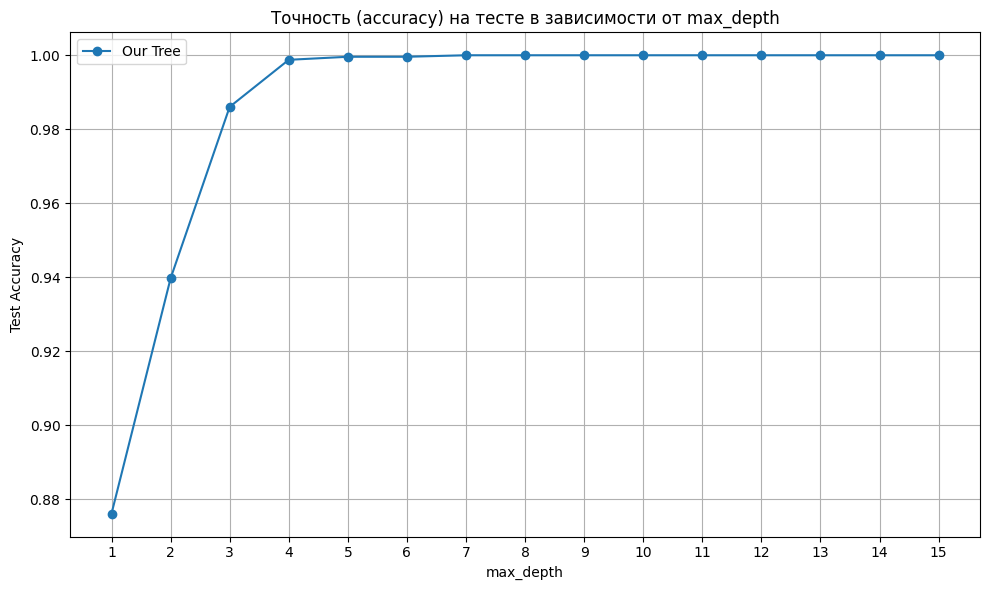

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

depths = list(range(1, 16))
acc_custom = []

for d in depths:
    # Custom Tree
    custom_tree = MyDecisionTreeClassifier(max_depth=d)
    custom_tree.fit(X_train, y_train)
    y_pred_custom = custom_tree.predict(X_test)
    acc_custom.append(accuracy_score(y_test, y_pred_custom))

plt.figure(figsize=(10, 6))
plt.plot(depths, acc_custom, marker='o', label='Our Tree')
plt.title('Точность (accuracy) на тесте в зависимости от max_depth')
plt.xlabel('max_depth')
plt.ylabel('Test Accuracy')
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Теперь ты умеешь

- Создавать фундаментальные элементы дерева:

 - узлы-листья, отвечающие за итоговые прогнозы классов;

 - узлы-навигации, которые направляют поток данных по веткам дерева;
 - метод батч-предсказания для эффективной обработки целых наборов данных.


- Создавать собственный класс для построения деревьев классификации.  
- Видеть механику деревьев принятия решений.

- Настраивать ключевые гиперпараметры дерева решений.
